# Assignment 5 - S8 Swiss Small-Cap Quality

Smaller Swiss stocks with liquidity, profitability, quality, and volatility controls.

## 1. Imports and Paths

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt


def find_course_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'data' / 'market_data.parquet').exists() and (candidate / 'src').exists():
            return candidate
        nested = candidate / 'qpmwp-course'
        if (nested / 'data' / 'market_data.parquet').exists() and (nested / 'src').exists():
            return nested
    raise FileNotFoundError('Could not locate qpmwp-course.')


COURSE_ROOT = find_course_root()
DATA_PATH = COURSE_ROOT / 'data'
SRC_PATH = COURSE_ROOT / 'src'

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print('COURSE_ROOT:', COURSE_ROOT)
print('DATA_PATH:', DATA_PATH)

COURSE_ROOT: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course
DATA_PATH: /Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/data


In [2]:
from helper_functions import load_data_spi, align_market_data_with_jkp_data
from optimization.optimization import Optimization, Objective
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)

## 2. Data

In [3]:
market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())

market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30


## 3. Parameters

In [4]:
N_MONTHS = 3
START_DATE = '2003-01-01'

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002
HIGH_SMALL_CAP_VARIABLE_COSTS = 0.005

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 250_000
FUNDAMENTAL_LAG_DAYS = 90
FUNDAMENTAL_LOOKBACK_DAYS = 460
RISK_LOOKBACK_DAYS = 252 * 2

SMALL_CAP_MAX_PERCENTILE = 0.75
PROFITABILITY_FIELDS = ['gp_at', 'op_at', 'cop_at']
QUALITY_FIELDS = ['qmj', 'qmj_prof', 'f_score', 'z_score']
FRESHNESS_FIELDS = sorted(set(PROFITABILITY_FIELDS + QUALITY_FIELDS))

MIN_POSITIVE_PROFITABILITY_FIELDS = 1
MIN_QUALITY_PERCENTILE = 0.20
MAX_VOL_PERCENTILE = 0.90
MAX_STOCK_WEIGHT = 0.12

print('Small-cap cutoff percentile:', SMALL_CAP_MAX_PERCENTILE)
print('Minimum median liquidity:', MIN_MEDIAN_LIQUIDITY)

Small-cap cutoff percentile: 0.75
Minimum median liquidity: 250000


## 4. Builder Functions

In [5]:
def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def latest_lagged_jkp(bs, rebdate, fields, lag_days=90, lookback_days=460):
    fields = [field for field in fields if field in bs.data.jkp_data.columns]
    if not fields:
        raise ValueError('None of the requested JKP fields exist in jkp_data.')

    cutoff = pd.to_datetime(rebdate) - pd.Timedelta(days=lag_days)
    start = cutoff - pd.Timedelta(days=lookback_days)
    dates = bs.data.jkp_data.index.get_level_values('date')
    window = bs.data.jkp_data.loc[(dates <= cutoff) & (dates >= start), fields]
    return window.groupby(level='id').last()


def latest_market_field(bs, rebdate, field):
    df = bs.data.market_data[[field]]
    dates = df.index.get_level_values('date')
    latest = df.loc[dates <= pd.to_datetime(rebdate), field].groupby(level='id').last()
    latest = latest[~latest.index.duplicated(keep='last')]
    return latest


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RETURN_HISTORY_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= kwargs.get('min_obs', MIN_RETURN_OBS)).astype(int),
    })


def bibfn_selection_small_cap(bs, rebdate, **kwargs):
    mktcap = latest_market_field(bs, rebdate, 'mktcap')
    ids = current_selected_ids(bs, mktcap.index)
    mktcap = mktcap.reindex(ids)
    threshold = mktcap.quantile(kwargs.get('max_percentile', SMALL_CAP_MAX_PERCENTILE))

    return pd.DataFrame({
        'values': mktcap,
        'binary': (mktcap.gt(0) & mktcap.le(threshold)).fillna(False).astype(int),
    })


def bibfn_selection_fundamental_freshness(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', FRESHNESS_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    non_missing = latest.notna().sum(axis=1)

    return pd.DataFrame({
        'values': non_missing,
        'binary': (non_missing >= 3).astype(int),
    })


def bibfn_selection_positive_profitability(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', PROFITABILITY_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    positive_count = latest.gt(0).sum(axis=1)

    return pd.DataFrame({
        'values': positive_count,
        'binary': (positive_count >= kwargs.get('min_positive', MIN_POSITIVE_PROFITABILITY_FIELDS)).astype(int),
    })


def bibfn_selection_quality_floor(bs, rebdate, **kwargs):
    latest = latest_lagged_jkp(
        bs,
        rebdate,
        kwargs.get('fields', QUALITY_FIELDS),
        kwargs.get('lag_days', FUNDAMENTAL_LAG_DAYS),
        kwargs.get('lookback_days', FUNDAMENTAL_LOOKBACK_DAYS),
    )
    ids = current_selected_ids(bs, latest.index)
    latest = latest.reindex(ids)
    quality = latest.rank(pct=True).mean(axis=1)
    threshold = quality.quantile(kwargs.get('min_percentile', MIN_QUALITY_PERCENTILE))

    return pd.DataFrame({
        'values': quality,
        'binary': quality.ge(threshold).fillna(False).astype(int),
    })


def bibfn_selection_volatility_cap(bs, rebdate, **kwargs):
    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=kwargs.get('width', RISK_LOOKBACK_DAYS),
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    vol = ret.std(axis=0) * np.sqrt(252)
    threshold = vol.quantile(kwargs.get('max_percentile', MAX_VOL_PERCENTILE))

    return pd.DataFrame({
        'values': vol,
        'binary': vol.le(threshold).fillna(False).astype(int),
    })


def cap_and_redistribute(weights, cap):
    weights = weights.copy().astype(float)
    if weights.empty:
        return weights
    if len(weights) * cap < 1:
        return weights / weights.sum()

    free = pd.Index(weights.index)
    capped = pd.Series(0.0, index=weights.index)
    remaining = 1.0

    while len(free) > 0:
        scaled = weights.loc[free] / weights.loc[free].sum() * remaining
        over = scaled > cap
        if not over.any():
            capped.loc[free] = scaled
            break
        capped.loc[scaled[over].index] = cap
        remaining = 1.0 - capped.sum()
        free = scaled[~over].index

    return capped / capped.sum()


class SmallCapInverseVolatilityPortfolio(Optimization):
    def __init__(self, max_weight=MAX_STOCK_WEIGHT, **kwargs):
        super().__init__(max_weight=max_weight, solver_name='no-solver-used', **kwargs)

    def set_objective(self, optimization_data):
        ret = optimization_data['return_series']
        vol = ret.std(axis=0) * np.sqrt(252)
        inv_vol = 1 / vol.replace(0, np.nan)
        self.objective = Objective(raw_weight=inv_vol.dropna())

    def solve(self):
        raw_weight = self.objective.coefficients['raw_weight']
        weights = raw_weight / raw_weight.sum()
        weights = cap_and_redistribute(weights, self.params['max_weight'])
        self.results.update({'weights': weights.to_dict(), 'status': True})
        return None


class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)

## 5. Rebalancing Dates

In [6]:
jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])

Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6. Backtest

In [7]:
selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'small_cap': SelectionItemBuilder(
        bibfn=bibfn_selection_small_cap,
        max_percentile=SMALL_CAP_MAX_PERCENTILE,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
    'fundamental_freshness': SelectionItemBuilder(
        bibfn=bibfn_selection_fundamental_freshness,
        fields=FRESHNESS_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'positive_profitability': SelectionItemBuilder(
        bibfn=bibfn_selection_positive_profitability,
        fields=PROFITABILITY_FIELDS,
        min_positive=MIN_POSITIVE_PROFITABILITY_FIELDS,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'quality_floor': SelectionItemBuilder(
        bibfn=bibfn_selection_quality_floor,
        fields=QUALITY_FIELDS,
        min_percentile=MIN_QUALITY_PERCENTILE,
        lag_days=FUNDAMENTAL_LAG_DAYS,
        lookback_days=FUNDAMENTAL_LOOKBACK_DAYS,
    ),
    'volatility_cap': SelectionItemBuilder(
        bibfn=bibfn_selection_volatility_cap,
        width=RISK_LOOKBACK_DAYS,
        max_percentile=MAX_VOL_PERCENTILE,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=RISK_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
}

optimization = SmallCapInverseVolatilityPortfolio(max_weight=MAX_STOCK_WEIGHT)

bs_s8 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=True,
)

bt_s8 = Backtest()
bt_s8.run(bs=bs_s8)

weights_s8 = bt_s8.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s8.shape)
print('Average holdings:', weights_s8.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s8.max(axis=1).mean().round(3))

Backtest completed.
Weight matrix: (85, 144)
Average holdings: 40.6
Average max stock weight: 0.074


## 7. Returns

In [8]:
return_series = data.get_return_series(weekdays_only=False)

s8_gross_returns = bt_s8.strategy.simulate(
    return_series=return_series,
    fc=0,
    vc=0,
)
s8_gross_returns.name = 'S8 gross'

s8_net_returns = bt_s8.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s8_net_returns.name = 'S8 net'

s8_high_cost_returns = bt_s8.strategy.simulate(
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=HIGH_SMALL_CAP_VARIABLE_COSTS,
)
s8_high_cost_returns.name = 'S8 high-cost net'

comparison = pd.concat(
    {
        'S8 net': s8_net_returns,
        'S8 high-cost net': s8_high_cost_returns,
        'S8 gross': s8_gross_returns,
        'SPI': data.bm_series,
    },
    axis=1,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)

/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


2003-02-03 to 2024-04-30
                   count      mean       std       min       25%       50%  \
S8 net            5609.0  0.000329  0.007933 -0.077937 -0.002989  0.000518   
S8 high-cost net  5609.0  0.000313  0.007931 -0.077937 -0.003001  0.000508   
S8 gross          5609.0  0.000394  0.007935 -0.077898 -0.002943  0.000575   
SPI               5609.0  0.000332  0.009932 -0.091109 -0.004052  0.000350   

                       75%       max  
S8 net            0.004317  0.066075  
S8 high-cost net  0.004306  0.066075  
S8 gross          0.004396  0.066114  
SPI               0.005263  0.105788  


/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  portf_ret[0] -= varcost[0]
/Users/michalandrzejewski/Desktop/Projects_Eth/new_qpmwp/qpmwp-course/src/backtesting/strategy.py:195: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  portf_ret[0] -= varcost[0]


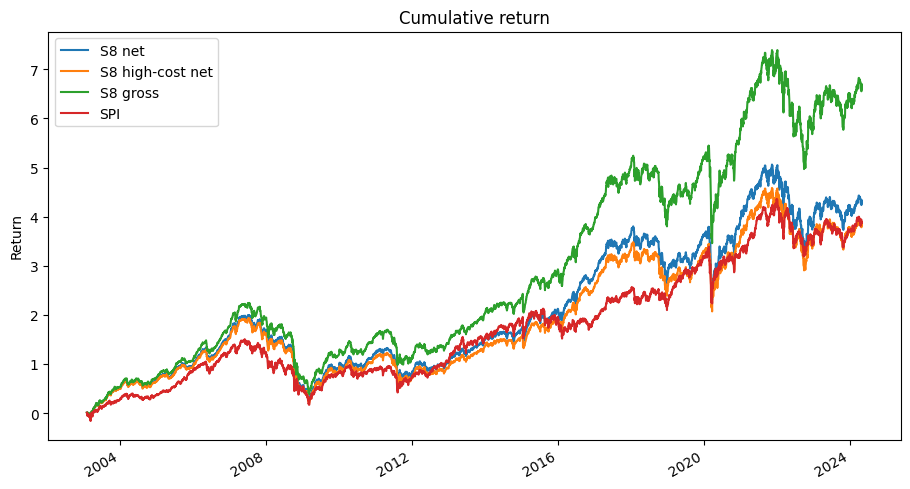

In [9]:
ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Return')
plt.show()

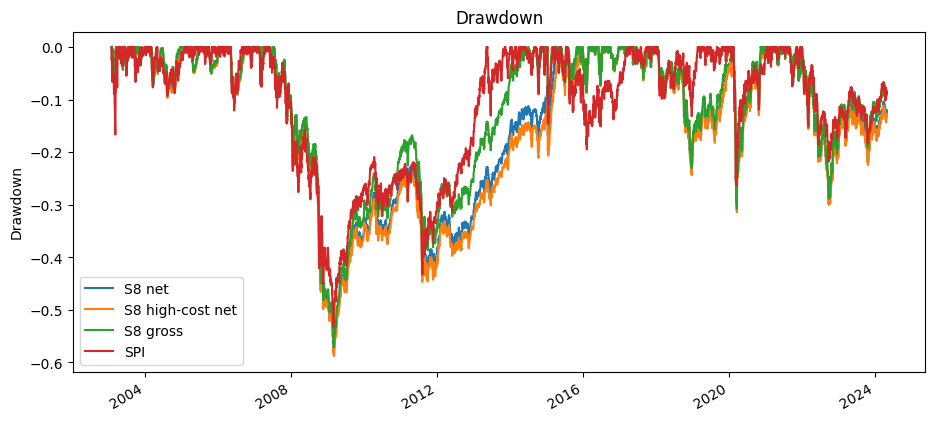

In [10]:
def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    peak = wealth.cummax()
    return wealth / peak - 1


ax = drawdown(comparison).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
plt.show()

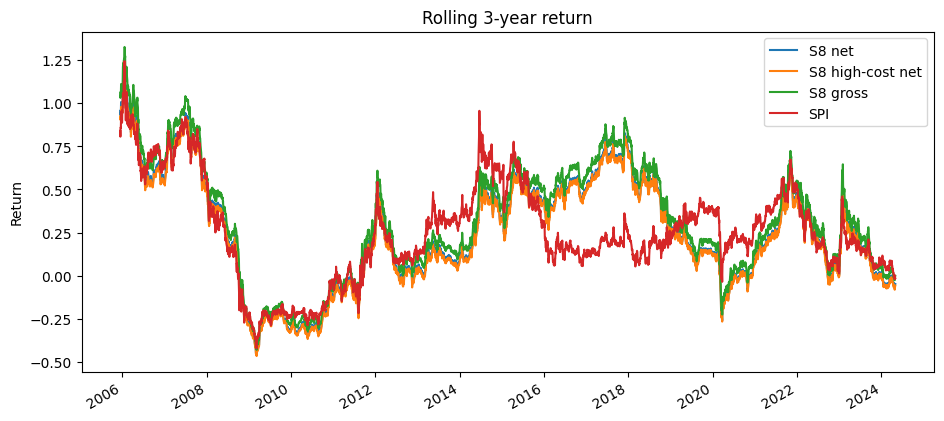

In [11]:
rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return.plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Return')
plt.show()

## 8. Statistics

In [12]:
def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats.style.format('{:.2%}')

In [13]:
turnover_s8 = bt_s8.strategy.turnover(return_series=return_series, rescale=False)

print('Average turnover:', turnover_s8.mean().round(3))
print('Median turnover:', turnover_s8.median().round(3))

turnover_s8.describe().to_frame('turnover')

Average turnover: 0.354
Median turnover: 0.338


,turnover
count,85.000000
mean,0.354451
std,0.147581
min,0.147343
25%,0.254923
50%,0.337687
75%,0.413316
max,1.000000


## 9. Selection Diagnostics

In [14]:
selection_counts = []

for rebdate in rebdates:
    bs_s8.build_selection(rebdate)
    binary = bs_s8.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()

,return_history,small_cap,gaps,min_volume,fundamental_freshness,positive_profitability,quality_floor,volatility_cap,selected_after_all_filters
2023-01-31,57.0,57.0,57.0,57.0,57.0,57.0,57.0,51.0,51.0
2023-04-30,57.0,57.0,57.0,57.0,57.0,57.0,57.0,51.0,51.0
2023-07-31,53.0,53.0,53.0,53.0,53.0,53.0,53.0,47.0,47.0
2023-10-31,53.0,53.0,53.0,53.0,53.0,53.0,53.0,47.0,47.0
2024-01-31,53.0,53.0,53.0,53.0,53.0,53.0,53.0,47.0,47.0


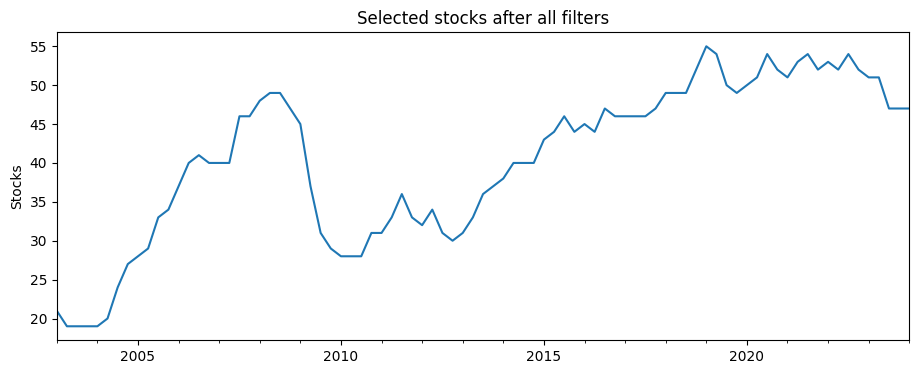

In [15]:
ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Selected stocks after all filters',
)
ax.set_ylabel('Stocks')
plt.show()

## 10. Summary

S8 excludes the largest Swiss stocks, keeps tradable and profitable smaller names, removes extreme-volatility stocks, and uses capped inverse-volatility weights. A higher transaction-cost line is included for small-cap cost sensitivity.